## DATA TRANSFORMING

**DATA TRANSFORMING: Translation of Labels**

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report
from scipy import stats

In [ ]:
vector_df = pd.read_csv('/content/vectordata.csv')

In [ ]:
display(vector_df.head())

,Centre de santé,Genre (Gender),Âge (Age),Poids (Weight),Circonference du bras (Mua circumference),"Haute température.(temperature, Hyperpyrexia)",Fièvre depuis 48 heures(Fever 48 hrs),Fièvre au cours des 7 derniers jours (Fever in the last 7 days),Type de fièvre (Type of Fever),Perte de poids (Loss of Weight),...,Maladies diagnostiquées/Paludisme (Malaria),Maladies diagnostiquées/Dengue,Maladies diagnostiquées/Chikunguya,Maladies diagnostiquées/Fièvre jaune (yellow fever),Maladies diagnostiquées/Fièvre Typhoïde (Thyphoid fever),Maladies diagnostiquées/Zika,Maladies diagnostiquées/Autres maladies diagnostiqué (Others diseases),Maladies diagnostiquées/Option 8,Autres maladies présentées par le patient,_uuid
0,CMA de DO,Femme,18,55.0,NaN,OUI,OUI,OUI,Récurrente,NON,...,1,1,0,0,0,0,0,0,NaN,df22d899-23a3-4c49-8059-6208c130f57d
1,CMA de DO,Homme,26,120.0,NaN,OUI,OUI,OUI,Récurrente,NON,...,1,1,0,0,0,0,0,0,NaN,4a7ef2f3-4ff0-4215-8cb5-20ba8c8d4355
2,CMA de DO,Homme,25,63.0,NaN,OUI,OUI,OUI,Récurrente,NON,...,1,0,0,0,1,0,0,0,NaN,104f6bc8-f39a-482b-b680-7ac1f8cccc86
3,CMA de DO,Homme,3,12.0,"13,5",OUI,OUI,NON,Récurrente,NON,...,1,0,0,0,0,0,0,0,NaN,26d7d04a-1a1c-4d4b-b64a-606f968e6d9c
4,CMA de DO,Homme,8,24.0,NaN,OUI,OUI,NON,Récurrente,NON,...,1,0,0,0,0,0,0,0,NaN,eb694f52-51ff-488d-9beb-2923a572a4cf


In [ ]:
column_translation = {
    "Centre de santédry": "Health Center",
    "Genre (Gender)": "Gender",
    "Âge (Age)": "Age",
    "Poids (Weight)": "Weight",
    "Circonference du bras (Mua circumference)": "Arm Circumference",
    "Haute température.(temperature, Hyperpyrexia)": "High Temperature",
    "Fièvre depuis 48 heures(Fever 48 hrs)": "Fever 48 Hours",
    "Fièvre au cours des 7 derniers jours (Fever in the last 7 days)": "Fever Last 7 Days",
    "Type de fièvre (Type of Fever)": "Fever Type",
    "Perte de poids (Loss of Weight)": "Weight Loss",
    "Maux de tête (headache)": "Headache",
    "Nausée (Nausea)": "Nausea",
    "Vomissement (Vomiting)": "Vomiting",
    "Douleur articulaire (Joint pain)": "Joint Pain",
    "Gonflement des articulations (Joint Swelling)": "Joint Swelling",
    "Douleur musculaire ( Muscle pain)": "Muscle Pain",
    "Douleur Thoracique (Chaist pain)": "Chest Pain",
    "Mal de dos / Douleur rachidienne ( Back pain / Rachiodynia)": "Back Pain",
    "Troubles de la conscience (Consciousness trouble)": "Consciousness Trouble",
    "Perte d'appétit ou Anorexie (Loss of appetite or Anorexia)": "Loss of appetite or Anorexia",
    "Éruptions cutanées ou Exanthème (Skin rash or Exanthema)": "Skin rash or Exanthema",
    "Éruption morbilliforme (Morbilliform rash)": "Morbilliform rash",
    "Saignement/ Manifestations hémorragiques (Bleeding)": "Bleeding",
    "Rhinorrhée (Rhinorrhea)": "Rhinorrhea",
    "Somnolence ou léthargie (Drowsiness or lethargy)": "Drowsiness or lethargy",
    "Vertige (Dizzy)": "Dizzy",
    "Inflammation de conjonctivite": "Conjunctivitis",
    "Douleur abdominale (stomac pain)": "Stomach pain",
    "Distension abdominale (Ventre gonflé) (Abdominal Distension (Swelling Stomach)/ Ascites)": "Abdominal Distension (Swelling Stomach)/ Ascites)",
    "Mal de gorge (throat pain)" : "throat pain",
    "Toux (Cough)": "Cough",
    "Diarrhée (Diarrhea)": "Diarrhea",
    "Douleur rétro-orbitrale (Retro-orbital pain)": "Retro-orbital pain",
    "Céphalée (Headache)": "Headache",
    "Sensation de frissons ou de froid (Shiver or cold sensation)": "Shiver or cold sensation",
    "Mictions fréquentes.(Frequent Urination)": "Frequent Urination",
    "Mictions fréquentes. (Frequent Urination)": "Frequent Urination",
    "Test TDR": "Rapid Test",
    "Epistaxis ((Bleeding nose)": "Bleeding nose",
    "Goutte épaisse": "Blood smear",
    "Hémoconcentration": "Hemoconcentration",
    "Goût amer dans la gorge (Bitter taste in your Throat)": "Bitter taste in your Throat",
    "Test de garrot positif (Positive tourniquet test)": "Positive tourniquet test",
    "Insuffisance cardiaque ou Myocardite(Heart failure or Myocarditis)": "Heart failure or Myocarditis",
    "Asthme (Astma)": "Asthma",
    "Pâleur cutanéo muqueuse ou Anémie (Mucosal skin pallor or Anemia)": "Pallor or Anemia",
    "Hypoglycémie (Hypoglycemia)": "Hypoglycemia",
    "Paludisme (Malaria)": "Malaria",
    "Drépanocytose": "Sickle Cell Disease",
    "Dengue (Dengua)": "Dengue",
    "Diabète": "Diabetes",
    "Arthrose": "Osteoarthritis",
    "Splénomégalie modérée": "Splenomegaly",
    "Dengue dans le menage (Household Dengue)": "Household Dengue",
    "Maladies diagnostiquées/Dengue": "Diagnosed: Dengue",
    "Maladies diagnostiquées/Fièvre Typhoïde (Thyphoid fever)": "Diagnosed: Typhoid Fever",
    "Maladies diagnostiquées/Zika": "Diagnosed: Zika",
    "Maladies diagnostiquées/Autres maladies diagnostiqué (Others diseases)": "Diagnosed: Other Diseases",
    "Maladies diagnostiquées/Paludisme (Malaria)": "Diagnosed: Malaria",
    "Maladies diagnostiquées/Chikunguya": "Diagnosed: Chikungunya",
    "Maladies diagnostiquées/Fièvre jaune (yellow fever)": "Diagnosed: Yellow Fever",
    "Maladies diagnostiquées/Option 8": "Diagnosed: Other",
    "Autres maladies présentées par le patient": "Other illnesses presented by patient",
    "Maladies diagnostiquées": "Diagnosed"
}

cleaned_column_translation = {}
for key, value in column_translation.items():
    # Apply the cleaning logic to the key
    cleaned_key = ' '.join(key.split())
    cleaned_key = cleaned_key.replace('Ã©', 'e').replace('Ã¨', 'e').replace('Â°C', 'C').replace('Â±', '').replace('.', '').replace('in', '').replace('-', '').replace('secs', '').replace('mmHg', '').replace('SD', '').replace('IQR', '').replace('beats', '').replace('breaths', '').replace('min', '')
    cleaned_key = cleaned_key.replace('  ', ' ') # Remove double spaces

    # Add the cleaned key and the original value to the new dictionary
    cleaned_column_translation[cleaned_key] = value

column_translation = cleaned_column_translation


# Translate columns
vector_df = vector_df.rename(columns=column_translation)

# Remove non-English characters and unnecessary letters from headers
vector_df.columns = vector_df.columns.str.replace(r'[\(\).,]', '', regex=True).str.strip()

In [ ]:
display(vector_df.columns)

Index(['Centre de santé', 'Gender', 'Age', 'Weight', 'Arm Circumference',
       'Haute températuretemperature Hyperpyrexia', 'Fever 48 Hours',
       'Fièvre au cours des 7 derniers jours Fever in the last 7 days',
       'Fever Type', 'Weight Loss',
       ...
       'Diagnosed: Malaria', 'Diagnosed: Dengue', 'Diagnosed: Chikungunya',
       'Diagnosed: Yellow Fever', 'Diagnosed: Typhoid Fever',
       'Diagnosed: Zika', 'Diagnosed: Other Diseases', 'Diagnosed: Other',
       'Other illnesses presented by patient', '_uuid'],
      dtype='object', length=109)

In [ ]:
vector_df.drop(columns=['_uuid', 'Health Center', 'Back Pain',
                         'Other illnesses presented by patient',
                         'Gender', 'Bitter taste in your Throat', 'Asthma', 'Diagnosed: Other'
                         'Prostration', 'Heart failure or Myocarditis', 'Osteoarthritis',
                            'Frequent Urination', 'Cancer', 'Diabète'
                            ], errors='ignore', inplace=True)

In [ ]:
print(vector_df.shape)

(299, 102)


## DATA CLEANING

**DATA CLEANING: Removing Unnecessary Features**

In [ ]:
# Calculate null percentages before dropping columns
null_percentages = vector_df.isnull().sum()/vector_df.shape[0]*100
null_percentages = null_percentages.sort_values(ascending=False)
display(null_percentages)

,0
Arm Circumference,91.638796
Temps de remplissage capillaire médiane secs IQR / Capillary refill time median secs IQR,69.565217
Pression artérielle moyenne mmHg ± SD / Arterial blood pressure mean mmHg ± SD,56.856187
Lymphocytes,50.836120
Hematocrite Hematrocrit,34.782609
...,...
Diagnosed: Yellow Fever,0.000000
Diagnosed: Typhoid Fever,0.000000
Diagnosed: Zika,0.000000
Diagnosed: Other Diseases,0.000000


In [ ]:
# Show null percentages higher than 30%
print("Null percentages higher than 30%:")
display(null_percentages[null_percentages > 30])

Null percentages higher than 30%:


,0
Arm Circumference,91.638796
Temps de remplissage capillaire médiane secs IQR / Capillary refill time median secs IQR,69.565217
Pression artérielle moyenne mmHg ± SD / Arterial blood pressure mean mmHg ± SD,56.856187
Lymphocytes,50.836120
Hematocrite Hematrocrit,34.782609
Weight,34.448161


In [ ]:
vector_df.replace({'OUI': 1, 'NON': 0}, inplace=True)
vector_df.replace({'Oui': 1, 'Non': 0}, inplace=True)
vector_df.replace({'Récurrente': 1, 'Intermittente': 0}, inplace=True)
vector_df.replace({'Positif': 1, 'Négatif': 0}, inplace=True)

# Replace comma with period in all columns, including 'Pulse rate (mean per minute ± SD)'
vector_df = vector_df.replace(',', '.', regex=True, inplace=False)

display(vector_df)

/tmp/ipython-input-10-677990157.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vector_df.replace({'OUI': 1, 'NON': 0}, inplace=True)
/tmp/ipython-input-10-677990157.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vector_df.replace({'Récurrente': 1, 'Intermittente': 0}, inplace=True)
/tmp/ipython-input-10-677990157.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the futu

,Centre de santé,Age,Weight,Arm Circumference,Haute températuretemperature Hyperpyrexia,Fever 48 Hours,Fièvre au cours des 7 derniers jours Fever in the last 7 days,Fever Type,Weight Loss,Headache,...,Dengue,Diagnosed,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases,Diagnosed: Other
0,CMA de DO,18,55.0,NaN,1,1.0,1.0,1.0,0.0,1.0,...,NaN,Paludisme (Malaria) Dengue,1,1,0,0,0,0,0,0
1,CMA de DO,26,120.0,NaN,1,1.0,1.0,1.0,0.0,1.0,...,1.0,Paludisme (Malaria) Dengue,1,1,0,0,0,0,0,0
2,CMA de DO,25,63.0,NaN,1,1.0,1.0,1.0,0.0,1.0,...,0.0,Paludisme (Malaria) Fièvre Typhoïde (Thyphoid ...,1,0,0,0,1,0,0,0
3,CMA de DO,3,12.0,13.5,1,1.0,0.0,1.0,0.0,1.0,...,0.0,Paludisme (Malaria),1,0,0,0,0,0,0,0
4,CMA de DO,8,24.0,NaN,1,1.0,0.0,1.0,0.0,1.0,...,0.0,Paludisme (Malaria),1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,CMA de DAFRA,9,21.0,NaN,1,1.0,0.0,0.0,0.0,1.0,...,0.0,Paludisme (Malaria) Fièvre jaune (yellow fever),1,0,0,1,0,0,0,0
295,CMA de DAFRA,6,19.0,NaN,1,1.0,0.0,0.0,0.0,1.0,...,0.0,Paludisme (Malaria),1,0,0,0,0,0,0,0
296,CMA de DAFRA,9,NaN,NaN,1,1.0,0.0,0.0,0.0,1.0,...,0.0,Paludisme (Malaria),1,0,0,0,0,0,0,0
297,CMA de DAFRA,7,16.0,NaN,1,1.0,0.0,0.0,0.0,1.0,...,0.0,Paludisme (Malaria),1,0,0,0,0,0,0,0


In [ ]:
vector_df.drop(columns=['Arm Circumference',
                        'Temps de remplissage capillaire (médiane secs IQR). / Capillary refill time (median secs IQR)',
                        'Pression artérielle (moyenne mmHg ± SD). / Arterial blood pressure (mean mmHg ± SD)'], errors='ignore', inplace=True)

print(vector_df.shape)

(299, 101)


In [ ]:
# Removes noise in age column
vector_df = vector_df[~vector_df['Age'].isin(['15-Dec', '07-Dec'])]
display(vector_df.shape)

(297, 101)

In [ ]:
#The removed download portion of the translated_vector_data.csv

The translated dataset has been saved as `translated_vector_data.csv`. You can download it from the files panel in the left sidebar.

In [ ]:
try:
    translated_df = pd.read_csv('/content/translated_vector_data_1.csv', encoding='utf-8')
except UnicodeDecodeError:
    try:
        translated_df = pd.read_csv('/content/translated_vector_data_1.csv', encoding='latin-1')
    except UnicodeDecodeError:
        translated_df = pd.read_csv('/content/translated_vector_data_1.csv', encoding='cp1252')

display(translated_df.head())

,Age,Weight,High Temperature,Fever 48 Hours,Fever Last 7 Days,Fever Type,Weight Loss,Headache,Nausea,Vomiting,...,Household Dengue,Dengue,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed Diseases,Diagnosed: Other Diseases
0,18.0,55.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,...,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,Paludisme (Malaria) Dengue,0
1,26.0,120.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,Paludisme (Malaria) Dengue,0
2,25.0,63.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,Paludisme (Malaria) Fièvre Typhoïde (Thyphoid ...,0
3,3.0,12.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Paludisme (Malaria),0
4,8.0,24.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Paludisme (Malaria),0


/tmp/ipython-input-15-1165604878.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=vector_df, x=col, palette="Set2")
/tmp/ipython-input-15-1165604878.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=vector_df, x=col, palette="Set2")
/tmp/ipython-input-15-1165604878.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=vector_df, x=col, palette="Set2")
/tmp/ipython-input-15-1165604878.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variab

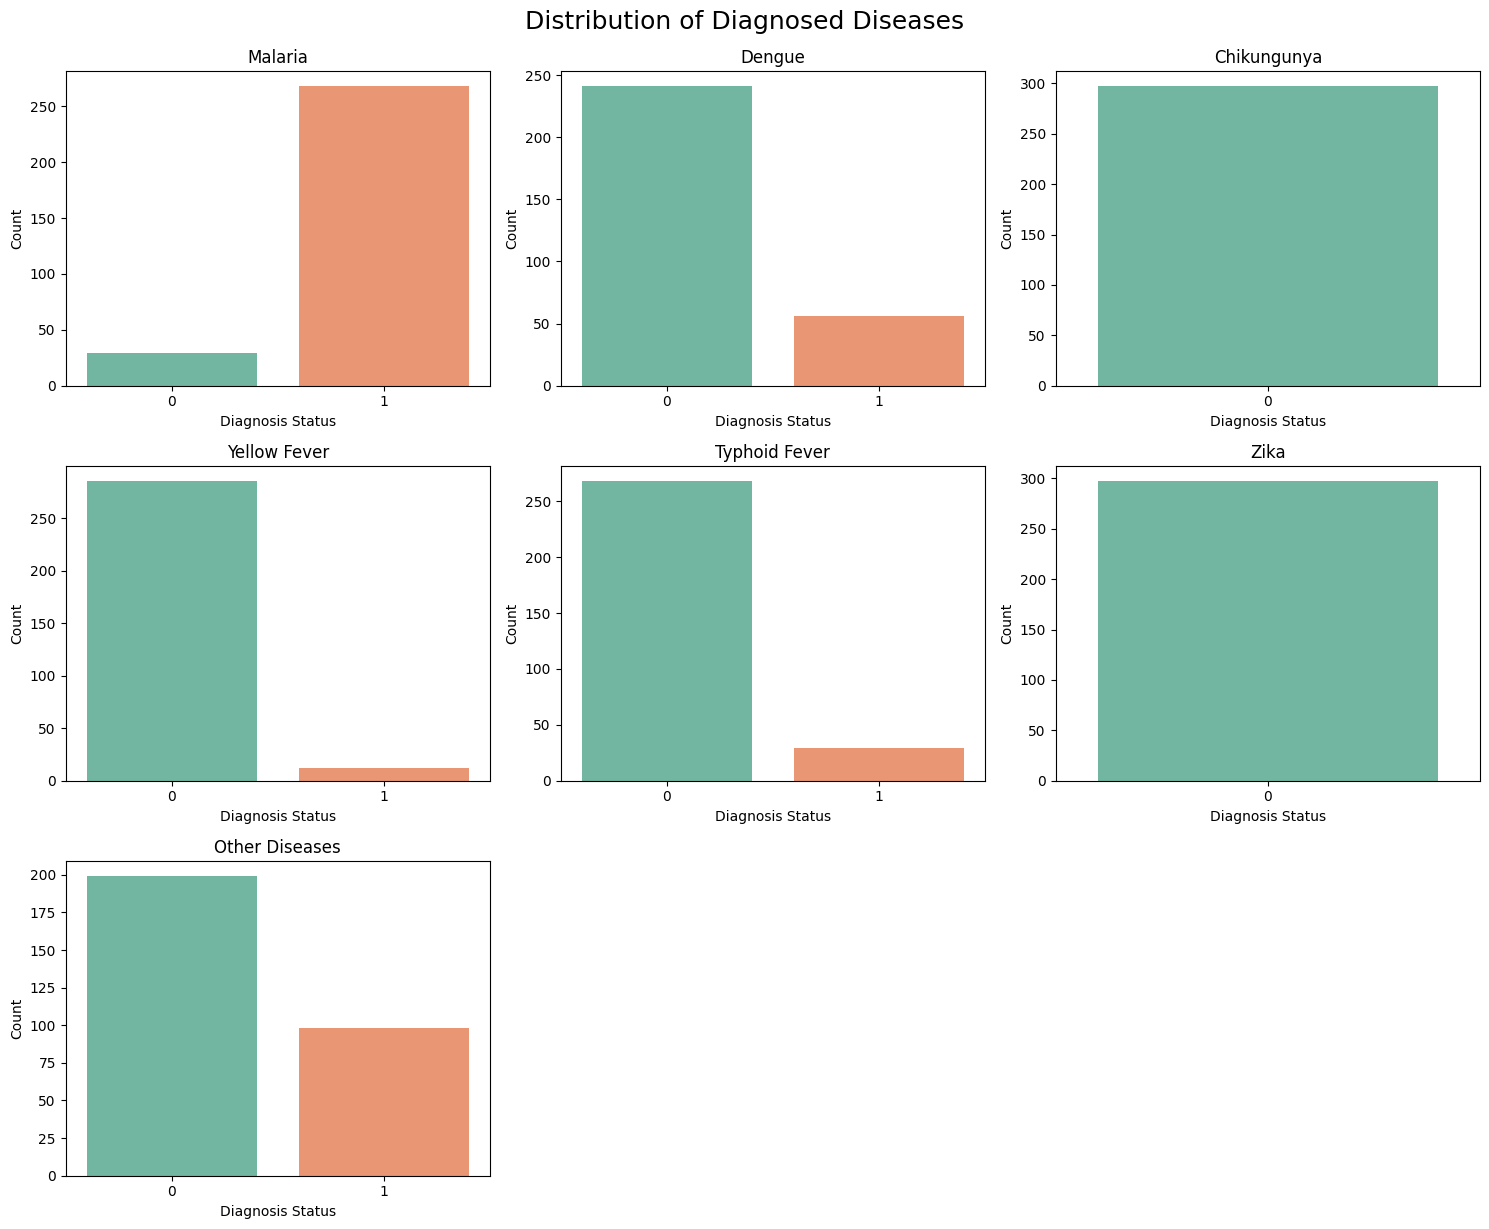

In [ ]:
# Identify diagnosis columns
diagnosed_cols = [col for col in translated_df.columns if col.startswith('Diagnosed:')]

# Set up the subplot grid (adjust columns/rows as needed)
n_cols = 3
n_rows = (len(diagnosed_cols) + n_cols - 1) // n_cols
plt.figure(figsize=(5 * n_cols, 4 * n_rows))

# Loop and plot each column
for i, col in enumerate(diagnosed_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.countplot(data=vector_df, x=col, palette="Set2")
    plt.title(col.replace("Diagnosed:", "").strip())
    plt.xlabel('Diagnosis Status')
    plt.ylabel('Count')

plt.tight_layout()
plt.suptitle('Distribution of Diagnosed Diseases', fontsize=18, y=1.02)
plt.show()


In [ ]:
#trans part
diagnosis_eng = {
    'Paludisme (Malaria) Dengue': 'Malaria, Dengue',
    'Paludisme (Malaria) Fièvre Typhoïde (Thyphoid fever)': 'Malaria, Typhoid Fever',
    'Paludisme (Malaria)': 'Malaria',
    'Paludisme (Malaria) Chikunguya': 'Chikungunya',
    'Paludisme (Malaria) Fièvre jaune (yellow fever)': 'Yellow Fever',
    'Paludisme (Malaria) Autres maladies diagnostiqué (Others diseases)': 'Malaria, Other Diseases',
    'Paludisme (Malaria) Option 8': 'Malaria, Other Diseases',
    'Paludisme (Malaria) Dengue Autres maladies diagnostiqué (Others diseases)': 'Malaria, Dengue, Other Diseases',
    'Paludisme (Malaria) Fièvre Typhoïde (Thyphoid fever) Autres maladies diagnostiqué (Others diseases)': 'Malaria, Typhoid Fever, Other Diseases',
    'Paludisme (Malaria) Chikunguya Autres maladies diagnostiqué (Others diseases)': 'Malaria, Chikungunya, Other Diseases',
    'Dengue Autres maladies diagnostiqué (Others diseases)': 'Other Disease, Dengue',
    'Dengue Fièvre jaune (yellow fever)': 'Dengue, Yellow Fever',
    'Paludisme (Malaria) Fièvre jaune (yellow fever) Autres maladies diagnostiqué (Others diseases)': 'Malaria, Yellow Fever, Other Diseases',
    'Fièvre Typhoïde (Thyphoid fever)': 'Typhoid Fever',
    'Paludisme (Malaria) Dengue Fièvre Typhoïde (Thyphoid fever)': 'Malaria, Dengue, Typhoid Fever',
    'Fièvre jaune (yellow fever) Fièvre Typhoïde (Thyphoid fever)': 'Yellow Fever, Typhoid Fever',
    'Paludisme (Malaria) Dengue Fièvre jaune (yellow fever)': 'Malaria, Dengue, Yellow Fever',
    'Dengue Fièvre Typhoïde (Thyphoid fever)': 'Dengue, Typhoid Fever',
    'Autres maladies diagnostiqué (Others diseases)': 'Other Diseases',
    '(Malaria) Dengue': 'Malaria, Dengue'

}

translated_df['Diagnosed Diseases'] = translated_df['Diagnosed Diseases'].replace(diagnosis_eng)

display(translated_df['Diagnosed Diseases'].value_counts())

,count
Diagnosed Diseases,
Malaria,118
"Malaria, Other Diseases",74
"Malaria, Dengue",36
"Malaria, Typhoid Fever",24
Other Diseases,14
Dengue,8
Yellow Fever,8
"Malaria, Dengue, Other Diseases",4
"Other Disease, Dengue",3


In [ ]:
# Define the columns to impute based on the user's list and available columns
columns_to_impute = [
    'Age',
    'Respiratory rate (median breaths/min IQR)',
    'Pulse rate (mean beats/min ± SD)',
    'Fever 48 Hours',
    'Fever Last 7 Days',
    'High Temperature',  # Add 'High Temperature' to the list for imputation
    'Fever Type',
    'Retro-orbital pain',
    'Headache',
    'Muscle Pain',
    'Joint Pain',
    'Joint Swelling',
    'Vomiting',
    'Abdominal Distension',
    'Stomach pain',
    'Bleeding',
    'Bleeding nose',
    'Skin rash or Exanthema',
    'Morbilliform rash',
    'Positive tourniquet test',
    'Drowsiness or lethargy',
    'Shiver or cold sensation',
    'Profuse sweating',
    'Respiratory distress',
    'Cough',
    'Household Dengue',
    'Sickle Cell Disease'
]

In [ ]:
# Impute missing values
for col in columns_to_impute:
    if col in translated_df.columns:
        # Check data type to decide between median and mode
        if translated_df[col].dtype in ['int64', 'float64']:
            # Impute with median for numerical columns
            median_value = translated_df[col].median()
            translated_df[col] = translated_df[col].fillna(median_value)
            # Convert to integer type
            translated_df[col] = translated_df[col].astype(int)
        else:
            # Impute with mode for categorical/object columns
            mode_value = translated_df[col].mode()[0]
            translated_df[col] = translated_df[col].fillna(mode_value)
    else:
        print(f"Warning: Column '{col}' not found in the DataFrame.")

# Display the number of missing values after imputation for the specified columns
print("Missing values after imputation for specified columns:")
display(translated_df[columns_to_impute].isnull().sum())

Missing values after imputation for specified columns:


,0
Age,0
Respiratory rate (median breaths/min IQR),0
Pulse rate (mean beats/min ± SD),0
Fever 48 Hours,0
Fever Last 7 Days,0
High Temperature,0
Fever Type,0
Retro-orbital pain,0
Headache,0
Muscle Pain,0


In [ ]:
# Fever Binning
def fever_level(row):
    # Handle potential NaN values by converting to 0 before converting to int
    fever_48 = int(row.get('Fever 48 Hours', 0) or 0)
    fever_7d = int(row.get('Fever Last 7 Days', 0) or 0)
    temp = int(row.get('High Temperature', 0) or 0)
    score = fever_48 + fever_7d + temp
    if score == 0: return 'None'
    elif score == 1: return 'Mild'
    elif score == 2: return 'Moderate'
    else: return 'Severe'

translated_df['Fever_Level'] = translated_df.apply(fever_level, axis=1)
translated_df.drop(columns=[
    'Fever 48 Hours', # Update to translated column name
    'Fever Last 7 Days', # Update to translated column name
    'High Temperature' # Update to translated column name
], inplace=True)

display(translated_df.head())

,Age,Weight,Fever Type,Weight Loss,Headache,Nausea,Vomiting,Joint Pain,Joint Swelling,Muscle Pain,...,Dengue,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed Diseases,Diagnosed: Other Diseases,Fever_Level
0,18,55.0,1,0.0,1,1.0,0,1,0,1,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,"Malaria, Dengue",0,Severe
1,26,120.0,1,0.0,1,1.0,1,1,0,1,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,"Malaria, Dengue",0,Severe
2,25,63.0,1,0.0,1,0.0,1,1,0,1,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,"Malaria, Typhoid Fever",0,Severe
3,3,12.0,1,0.0,1,0.0,1,0,0,0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Malaria,0,Moderate
4,8,24.0,1,0.0,1,0.0,1,0,0,1,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Malaria,0,Moderate


In [ ]:
# Define the columns to keep
columns_to_keep = [
    'Age',
    'Fever_Level',
    'Respiratory rate (median breaths/min IQR)',
    'Pulse rate (mean beats/min ± SD)',
    'Retro-orbital pain',
    'Headache',
    'Muscle Pain',
    'Joint Pain',
    'Joint Swelling',
    'Vomiting',
    'Abdominal Distension',
    'Stomach pain',
    'Bleeding',
    'Bleeding nose',
    'Skin rash or Exanthema',
    'Morbilliform rash',
    'Positive tourniquet test',
    'Drowsiness or lethargy',
    'Shiver or cold sensation',
    'Profuse sweating',
    'Respiratory distress',
    'Cough',
    'Household Dengue',
    'Sickle Cell Disease',
    'Diagnosed Diseases',
    'Diagnosed: Malaria',
    'Diagnosed: Dengue',
    'Diagnosed: Chikungunya',
    'Diagnosed: Yellow Fever',
    'Diagnosed: Typhoid Fever',
    'Diagnosed: Zika',
    'Diagnosed: Other Diseases'
]

# Create a new DataFrame with only the specified columns
translated_df = translated_df[columns_to_keep]

# Display the shape of the new DataFrame
print("Shape of the DataFrame after removing columns:")
display(translated_df.shape)

# Display the first few rows of the new DataFrame
display(translated_df.head())

Shape of the DataFrame after removing columns:


(298, 32)

,Age,Fever_Level,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,...,Household Dengue,Sickle Cell Disease,Diagnosed Diseases,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases
0,18,Severe,26,131,0,1,1,1,0,0,...,0,0,"Malaria, Dengue",1.0,1.0,0.0,0.0,0.0,0.0,0
1,26,Severe,28,38,0,1,1,1,0,1,...,1,0,"Malaria, Dengue",1.0,1.0,0.0,0.0,0.0,0.0,0
2,25,Severe,22,100,0,1,1,1,0,1,...,0,0,"Malaria, Typhoid Fever",1.0,0.0,0.0,0.0,1.0,0.0,0
3,3,Moderate,26,88,0,1,0,0,0,1,...,0,0,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0
4,8,Moderate,32,109,0,1,1,0,0,1,...,0,0,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0


In [ ]:
translated_df.to_csv('processed_translated_data.csv', index=False)

The processed dataset has been saved as `processed_translated_data.csv`. You can download it from the files panel in the left sidebar.

# Decision Tree Model
Determines what type of vector borne disease the patient has depending on their symptoms

## Data collection and preparation

### Subtask:
Load the data from "/content/processed_translated_data.csv" into a pandas DataFrame and prepare the data for modeling, including handling categorical features and splitting the data into training and testing sets.


**Purpose**:
Loads the data, separate features and target, handle categorical features using one-hot encoding, and split the data into training and testing sets. We also remove diagnosed diseases to train and test if the model predicts the correct vector-borne disease according to symptoms.


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset
df = pd.read_csv('/content/processed_translated_data.csv')

# Identify and separate target variable
X = df.drop('Diagnosed Diseases', axis=1)
y = df['Diagnosed Diseases']

# Handle categorical features - One-hot encode 'Fever_Level'
X_cleaned = pd.get_dummies(X, columns=['Fever_Level'], dummy_na=True)

# Split the dataset
X_train_cleaned, X_test_cleaned, y_train_cleaned, y_test_cleaned = train_test_split(
    X_cleaned, y, test_size=0.2, random_state=42
)

display(X_train_cleaned.head())
display(X_test_cleaned.head())
display(y_train_cleaned.head())
display(y_test_cleaned.head())

,Age,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,Abdominal Distension,...,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases,Fever_Level_Mild,Fever_Level_Moderate,Fever_Level_Severe,Fever_Level_nan
6,2,32,109,0,0,0,0,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0,True,False,False,False
182,31,32,105,0,0,0,0,0,1,0,...,1.0,0.0,0.0,0.0,0.0,1,False,False,True,False
170,7,28,110,0,1,1,1,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0,False,True,False,False
146,14,32,131,0,1,1,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,False,False,True,False
30,4,32,109,0,1,0,0,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0,False,True,False,False


,Age,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,Abdominal Distension,...,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases,Fever_Level_Mild,Fever_Level_Moderate,Fever_Level_Severe,Fever_Level_nan
159,6,30,155,0,1,0,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,1,False,True,False,False
264,30,32,121,0,1,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,1,False,False,False,True
254,31,32,112,0,1,0,0,0,1,0,...,0.0,0.0,0.0,0.0,0.0,1,False,False,True,False
9,14,32,109,0,1,1,1,0,1,0,...,0.0,0.0,0.0,0.0,0.0,1,False,True,False,False
77,12,55,98,0,1,0,1,0,1,0,...,1.0,0.0,0.0,0.0,0.0,0,False,True,False,False


,Diagnosed Diseases
6,Malaria
182,"Malaria, Other Diseases"
170,Malaria
146,"Malaria, Dengue"
30,Dengue


,Diagnosed Diseases
159,"Malaria, Other Diseases"
264,"Malaria, Other Diseases"
254,"Malaria, Other Diseases"
9,"Malaria, Other Diseases"
77,"Malaria, Dengue"


## Feature selection

### Subtask:
Select relevant features from the dataset for training the decision tree model.


**Purpose**:
Before we train the RandomForestClassifier, we must first remove rows with NaNs from target variables (y_train_cleaned), secondly fill out missing values by imputing NaNs in our feature data (X_train_cleaned) using mean, and lastly we now train and conduct a feature selection based on their importance



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
import numpy as np
import pandas as pd

# Handle missing values in the target variable (y) by removing rows
nan_indices_train = y_train_cleaned.isna()
X_train_cleaned = X_train_cleaned[~nan_indices_train]
y_train_cleaned = y_train_cleaned[~nan_indices_train]

nan_indices_test = y_test_cleaned.isna()
X_test_cleaned = X_test_cleaned[~nan_indices_test]
y_test_cleaned = y_test_cleaned[~nan_indices_test]

# Impute missing values in features (X) using the mean
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
X_train_cleaned = pd.DataFrame(imputer.fit_transform(X_train_cleaned),
                               columns=X_train_cleaned.columns,
                               index=X_train_cleaned.index)
X_test_cleaned = pd.DataFrame(imputer.transform(X_test_cleaned),
                              columns=X_test_cleaned.columns,
                              index=X_test_cleaned.index)

# Train a RandomForestClassifier to get important features
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_cleaned, y_train_cleaned)

# Select features based on importance threshold (0.005)
feature_importances = pd.Series(
    rf_model.feature_importances_, index=X_train_cleaned.columns
).sort_values(ascending=False)

features_to_keep = feature_importances[feature_importances > 0.005].index.tolist()

# Filter DataFrames to keep only the selected features
X_train_filtered = X_train_cleaned[features_to_keep]
X_test_filtered = X_test_cleaned[features_to_keep]

# Display filtered data and chosen features
display(X_train_filtered.head())
display(X_test_filtered.head())
display(features_to_keep)

,Diagnosed: Other Diseases,Age,Pulse rate (mean beats/min ± SD),Respiratory rate (median breaths/min IQR),Shiver or cold sensation,Positive tourniquet test,Vomiting,Drowsiness or lethargy,Diagnosed: Typhoid Fever,Joint Pain,...,Fever_Level_Moderate,Diagnosed: Dengue,Respiratory distress,Diagnosed: Malaria,Fever_Level_Severe,Fever_Level_nan,Fever_Level_Mild,Retro-orbital pain,Abdominal Distension,Bleeding
6,0.0,2.0,109.0,32.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
182,1.0,31.0,105.0,32.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
170,0.0,7.0,110.0,28.0,1.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
146,0.0,14.0,131.0,32.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
30,0.0,4.0,109.0,32.0,1.0,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


,Diagnosed: Other Diseases,Age,Pulse rate (mean beats/min ± SD),Respiratory rate (median breaths/min IQR),Shiver or cold sensation,Positive tourniquet test,Vomiting,Drowsiness or lethargy,Diagnosed: Typhoid Fever,Joint Pain,...,Fever_Level_Moderate,Diagnosed: Dengue,Respiratory distress,Diagnosed: Malaria,Fever_Level_Severe,Fever_Level_nan,Fever_Level_Mild,Retro-orbital pain,Abdominal Distension,Bleeding
159,1.0,6.0,155.0,30.0,1.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
264,1.0,30.0,121.0,32.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
254,1.0,31.0,112.0,32.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
9,1.0,14.0,109.0,32.0,0.0,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
77,0.0,12.0,98.0,55.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


['Diagnosed: Other Diseases',
 'Age',
 'Pulse rate (mean beats/min ± SD)',
 'Respiratory rate (median breaths/min IQR)',
 'Shiver or cold sensation',
 'Positive tourniquet test',
 'Vomiting',
 'Drowsiness or lethargy',
 'Diagnosed: Typhoid Fever',
 'Joint Pain',
 'Muscle Pain',
 'Headache',
 'Stomach pain',
 'Cough',
 'Diagnosed: Yellow Fever',
 'Fever_Level_Moderate',
 'Diagnosed: Dengue',
 'Respiratory distress',
 'Diagnosed: Malaria',
 'Fever_Level_Severe',
 'Fever_Level_nan',
 'Fever_Level_Mild',
 'Retro-orbital pain',
 'Abdominal Distension',
 'Bleeding']

## Model building (recursive partitioning)

### Subtask:
Build an initial decision tree model using the training data.


**Purpose**:
Build an initial decision tree model using the training data.



In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create a DecisionTreeClassifier object
decision_tree_model = DecisionTreeClassifier(random_state=42)

# Train the decision tree model using the transformed dataset
decision_tree_model.fit(X_train_filtered, y_train_cleaned)

DecisionTreeClassifier(random_state=42)

## Model optimization (pruning)

### Subtask:
Optimize the decision tree model by applying pruning techniques to prevent overfitting and improve generalization.


**Purpose**:
Calculate the cost complexity pruning path, extract alpha values and impurities, train models for each alpha, calculate training and testing accuracies, and store them for plotting.



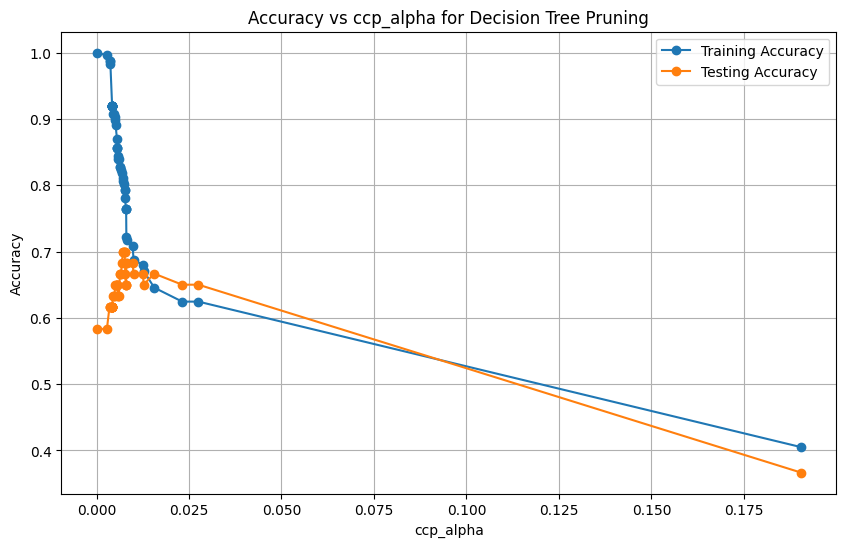

In [ ]:
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
w
# 1. Figure out the cost complexity pruning path
path = decision_tree_model.cost_complexity_pruning_path(X_train_filtered, y_train_cleaned)

# 2. Get the ccp_alpha values and how much they reduce impurity
ccp_alphas, impurities = path.ccp_alphas, path.impurities

# 3. Train a bunch of Decision Tree models, each with a different ccp_alpha
models = []
for ccp_alpha in ccp_alphas:
    model = DecisionTreeClassifier(random_state=42, ccp_alpha=ccp_alpha)
    model.fit(X_train_filtered, y_train_cleaned)
    models.append(model)

# 4. For each model, see how accurate it is on both the training and testing data
train_accuracies = []
test_accuracies = []

for model in models:
    train_accuracies.append(model.score(X_train_filtered, y_train_cleaned))
    test_accuracies.append(model.score(X_test_filtered, y_test_cleaned))

# 5. Plot the accuracy scores for training and testing against the ccp_alpha values
plt.figure(figsize=(10, 6))
plt.plot(ccp_alphas, train_accuracies, marker='o', label='Training Accuracy')
plt.plot(ccp_alphas, test_accuracies, marker='o', label='Testing Accuracy')
plt.xlabel('ccp_alpha')
plt.ylabel('Accuracy')
plt.title('Accuracy vs ccp_alpha for Decision Tree Pruning')
plt.legend()
plt.grid(True)
plt.show()

**Purpose**:
Identify the optimal ccp_alpha value that maximizes testing accuracy and train the final pruned Decision Tree model using this optimal alpha.



In [ ]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

# 6. Find the best ccp_alpha value that gives us the highest testing accuracy
optimal_ccp_alpha_index = np.argmax(test_accuracies)
optimal_ccp_alpha = ccp_alphas[optimal_ccp_alpha_index]

print(f'Optimal ccp_alpha: {optimal_ccp_alpha}')

# 7. Train the final pruned Decision Tree model using that best ccp_alpha value
pruned_decision_tree_model = DecisionTreeClassifier(random_state=42, ccp_alpha=optimal_ccp_alpha)
pruned_decision_tree_model.fit(X_train_filtered, y_train_cleaned)

Optimal ccp_alpha: 0.007172995780590715


DecisionTreeClassifier(ccp_alpha=np.float64(0.007172995780590715),
                       random_state=42)

## Evaluation and validation

### Subtask:
Evaluate the performance of the optimized decision tree model using appropriate metrics (accuracy, recall, precision, and F1-score) on the testing data.


**Purpose**:
Import the necessary metrics and calculate the performance metrics on both the train and test set using the latest pruned model with the best hyperparameter.



In [ ]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score # Import necessary metrics

# Make predictions on the filtered testing data
y_pred_test = pruned_decision_tree_model.predict(X_test_filtered)
y_pred_train = pruned_decision_tree_model.predict(X_train_filtered)


# Calculate how well the model did on the testing set
accuracy_test = accuracy_score(y_test_cleaned, y_pred_test)
recall_test = recall_score(y_test_cleaned, y_pred_test, average='weighted')
precision_test = precision_score(y_test_cleaned, y_pred_test, average='weighted')
f1_test = f1_score(y_test_cleaned, y_pred_test, average='weighted')

# Calculate how well the model did on the training set
accuracy_train = accuracy_score(y_train_cleaned, y_pred_train)
recall_train = recall_score(y_train_cleaned, y_pred_train, average='weighted')
precision_train = precision_score(y_train_cleaned, y_pred_train, average='weighted')
f1_train = f1_score(y_train_cleaned, y_pred_train, average='weighted')


# Show the results
print("--- Training Set Metrics ---")
print(f'Accuracy: {accuracy_train:.4f}')
print(f'Recall: {recall_train:.4f}')
print(f'Precision: {precision_train:.4f}')
print(f'F1-score: {f1_train:.4f}')

print("\n--- Test Set Metrics ---")
print(f'Accuracy: {accuracy_test:.4f}')
print(f'Recall: {recall_test:.4f}')
print(f'Precision: {precision_test:.4f}')
print(f'F1-score: {f1_test:.4f}')

--- Training Set Metrics ---
Accuracy: 0.8101
Recall: 0.8101
Precision: 0.7869
F1-score: 0.7809

--- Test Set Metrics ---
Accuracy: 0.7000
Recall: 0.7000
Precision: 0.6669
F1-score: 0.6788


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Prediction and inference

### Subtask:
Use the trained and optimized model to make predictions on new data.


**Purpose**:
Use the trained and optimized model to make predictions on the test data and display a few predictions of what type of vector-borne disease.



In [ ]:
# Use the trained and optimized model to guess the diseases
y_pred = pruned_decision_tree_model.predict(X_test_filtered)

# Show the first few guesses
print("First few predicted values:")
for item in y_pred[:10]:
    print("-", item)

First few predicted values:
- Malaria, Other Diseases
- Malaria, Dengue, Other Diseases
- Malaria, Other Diseases
- Malaria, Other Diseases
- Malaria
- Malaria
- Malaria, Typhoid Fever
- Malaria, Other Diseases
- Malaria
- Malaria, Other Diseases


## Visualization and Results

### Subtask:
Visualize the decision tree and summarize the model's performance and important features.


**Purpose**:
Visualize the pruned decision tree and summarize the model's test performance and how the model works.



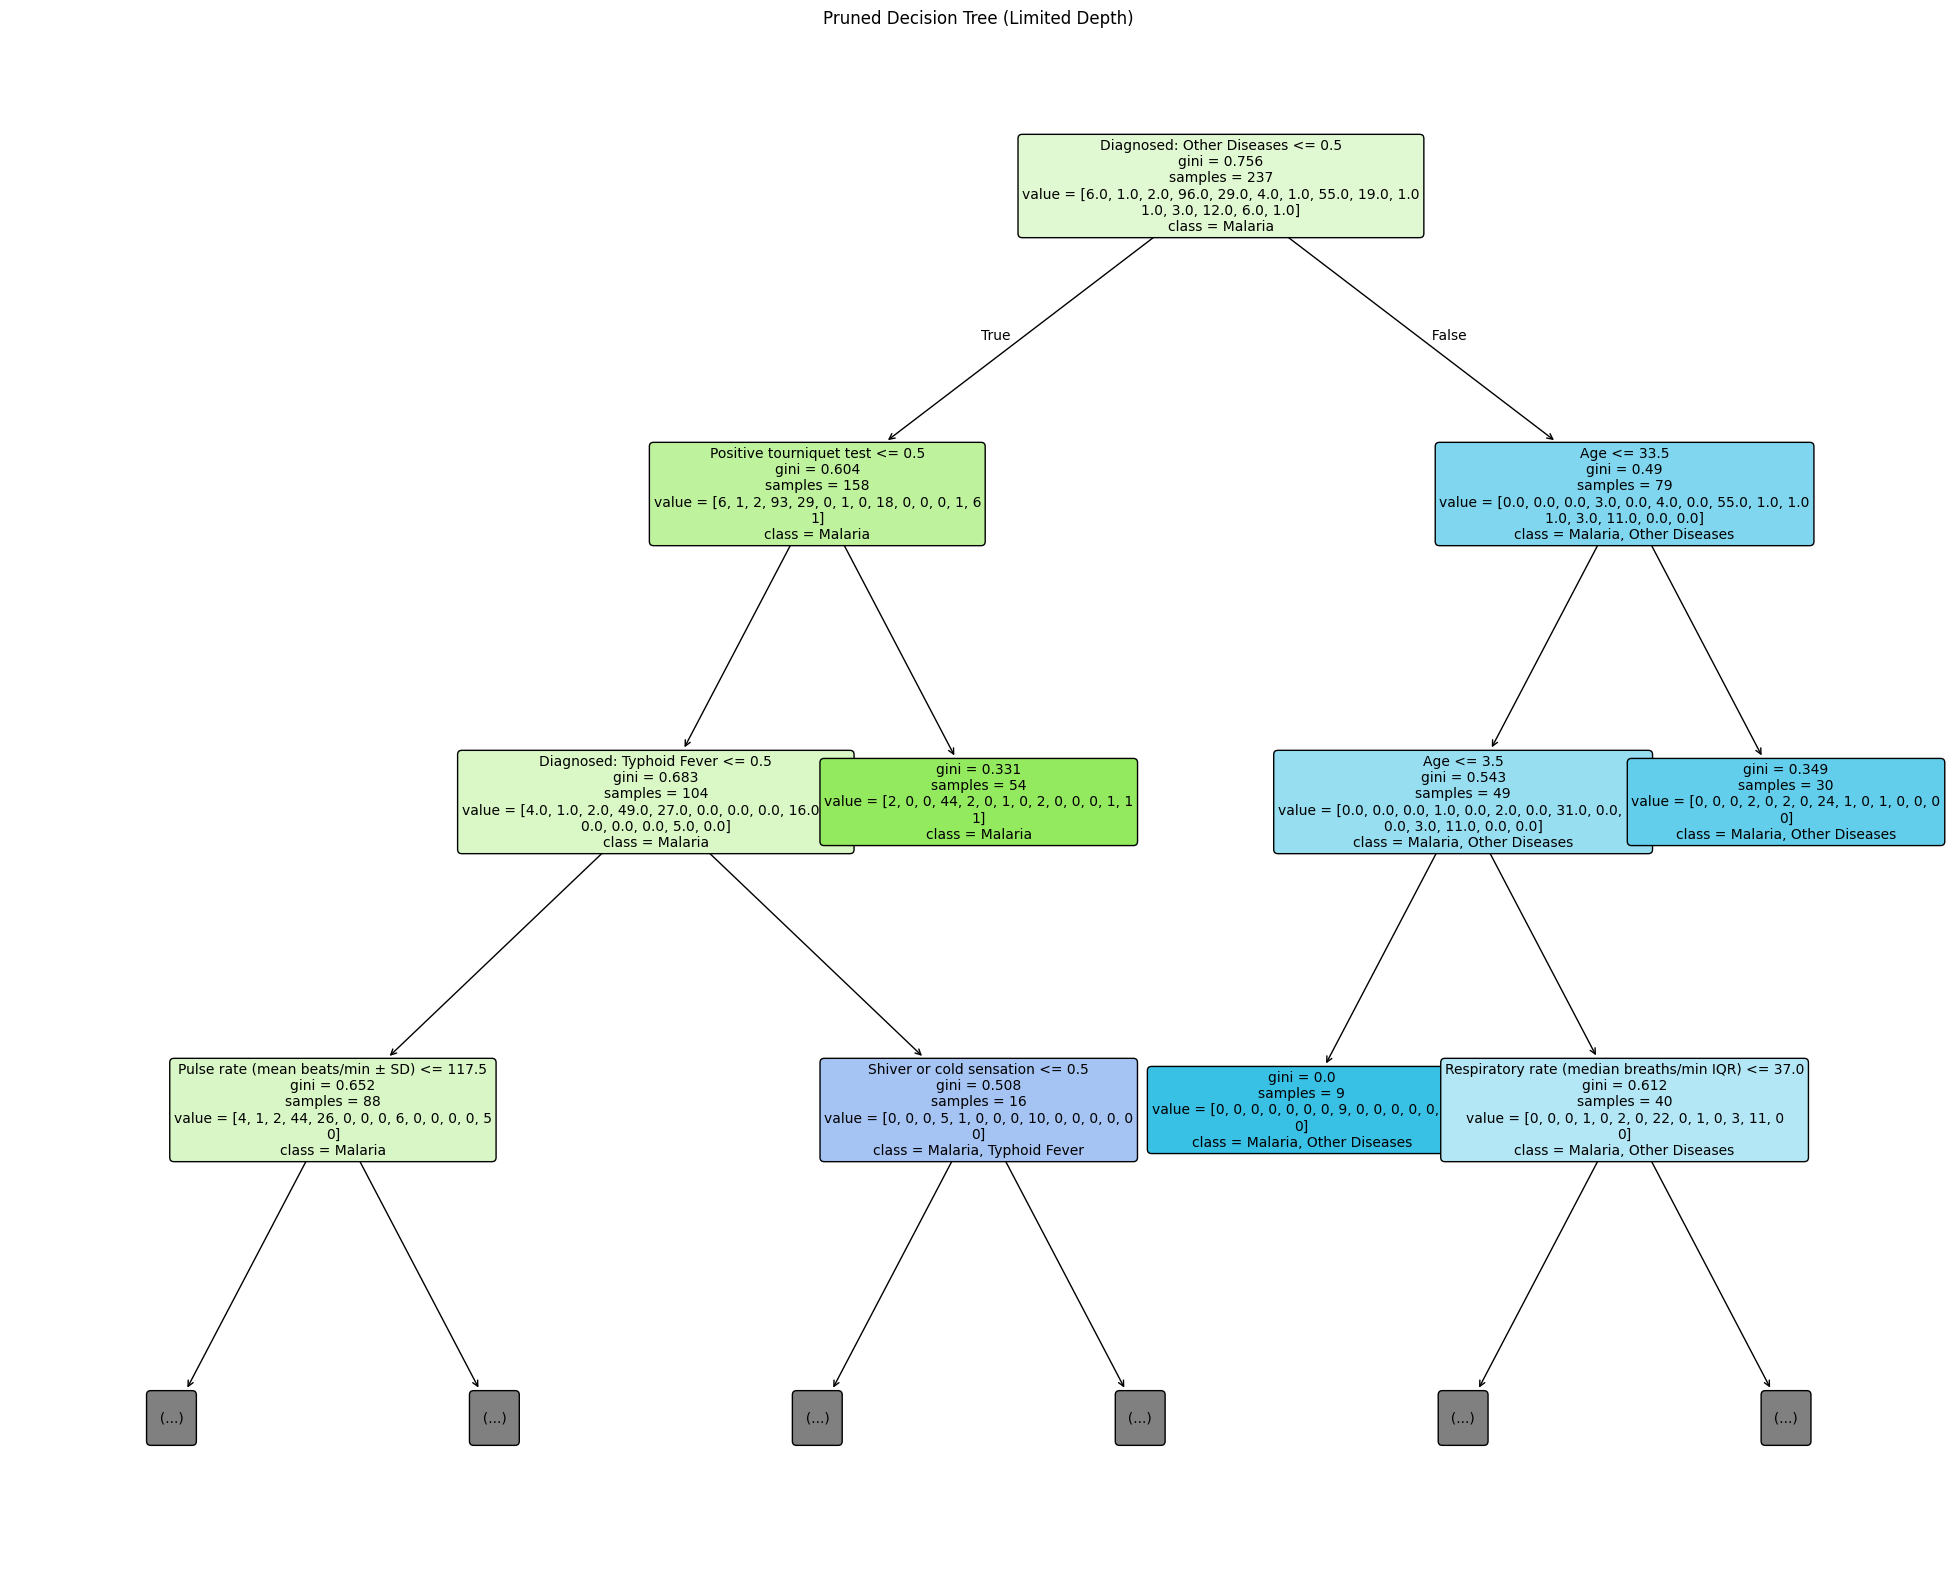

Model Performance Metrics:
Accuracy: 0.7000
Recall: 0.7000
Precision: 0.6669
F1-score: 0.6788
These numbers tell us how good the model is at figuring out the type of vector-borne disease on the test data.
An accuracy of 0.7000 means the model got the disease type right for 70.00% of the test cases.
A recall of 0.7000 (weighted average) means the model caught about 70.00% of all the actual cases for each disease type.
A precision of 0.6669 (weighted average) means that when the model said someone had a certain disease, it was right about 66.69% of the time, on average across all the disease types.
An F1-score of 0.6788 (weighted average) is a balanced measure of how well the model did, averaging 67.88% across all the disease types.

 Important Features:


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,0
Diagnosed: Other Diseases,0.203914
Pulse rate (mean beats/min ± SD),0.136975
Age,0.134663
Respiratory rate (median breaths/min IQR),0.085082
Shiver or cold sensation,0.033667
Positive tourniquet test,0.033128
Vomiting,0.031384
Drowsiness or lethargy,0.030406
Joint Pain,0.028148
Diagnosed: Typhoid Fever,0.027951


These feature importances show which features helped the model make its predictions the most.
Features with higher importance scores had a bigger impact on how the tree made its decisions.
The features that mattered most were: Diagnosed: Other Diseases (0.2039), Pulse rate (mean beats/min ± SD) (0.1370), and Age (0.1347).
This means these features were the most useful for predicting vector-borne diseases with this model.


In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score # Import necessary metrics

# Draw the decision tree - The decision tree is reduced for better visuals
plt.figure(figsize=(25, 20))
plot_tree(
    pruned_decision_tree_model,
    feature_names=X_train_filtered.columns,
    class_names=pruned_decision_tree_model.classes_,
    filled=True,
    rounded=True,
    fontsize=10, # Made the text bigger so it's easier to read
    max_depth=3 # Only show the top levels of the tree for a simpler picture
)
plt.title('Pruned Decision Tree (Limited Depth)')
plt.show()

# Calculate how well the model did for the printout
y_pred_test = pruned_decision_tree_model.predict(X_test_filtered)
accuracy = accuracy_score(y_test_cleaned, y_pred_test)
recall = recall_score(y_test_cleaned, y_pred_test, average='weighted')
precision = precision_score(y_test_cleaned, y_pred_test, average='weighted')
f1 = f1_score(y_test_cleaned, y_pred_test, average='weighted')


# Sum up how well the model performed
print("Model Performance Metrics:")
print(f'Accuracy: {accuracy:.4f}')
print(f'Recall: {recall:.4f}')
print(f'Precision: {precision:.4f}')
print(f'F1-score: {f1:.4f}')
print(
    "These numbers tell us how good the model is at figuring out the type of vector-borne disease on the test data."
)
print(
    f"An accuracy of {accuracy:.4f} means the model got the disease type right for {accuracy*100:.2f}% of the test cases."
)
print(
    f"A recall of {recall:.4f} (weighted average) means the model caught about {recall*100:.2f}% of all the actual cases for each disease type."
)
print(
    f"A precision of {precision:.4f} (weighted average) means that when the model said someone had a certain disease, it was right about {precision*100:.2f}% of the time, on average across all the disease types."
)
print(
    f"An F1-score of {f1:.4f} (weighted average) is a balanced measure of how well the model did, averaging {f1*100:.2f}% across all the disease types."
)

# Point out and talk about the features that mattered most
print("\n Important Features:")
# Figure out feature importances again based on the features we kept
rf_model_updated = RandomForestClassifier(random_state=42)
rf_model_updated.fit(X_train_filtered, y_train_cleaned)
feature_importances_updated = pd.Series(
    rf_model_updated.feature_importances_, index=X_train_filtered.columns
).sort_values(ascending=False)

display(feature_importances_updated)
print(
    "These feature importances show which features helped the model make its predictions the most."
)
print(
    "Features with higher importance scores had a bigger impact on how the tree made its decisions."
)
# Make sure there are at least 3 features before trying to show them
if len(feature_importances_updated) >= 3:
    print(
        f"The features that mattered most were: {feature_importances_updated.index[0]} ({feature_importances_updated.iloc[0]:.4f}),"
        f" {feature_importances_updated.index[1]} ({feature_importances_updated.iloc[1]:.4f}), and"
        f" {feature_importances_updated.index[2]} ({feature_importances_updated.iloc[2]:.4f})."
    )
elif len(feature_importances_updated) > 0:
     print("The most important features are:")
     for i in range(len(feature_importances_updated)):
         print(f"- {feature_importances_updated.index[i]} ({feature_importances_updated.iloc[i]:.4f})")
else:
    print("Couldn't find any important features based on our criteria.")

print(
    "This means these features were the most useful for predicting vector-borne diseases with this model."
)

## Confusion Matrix and Summary

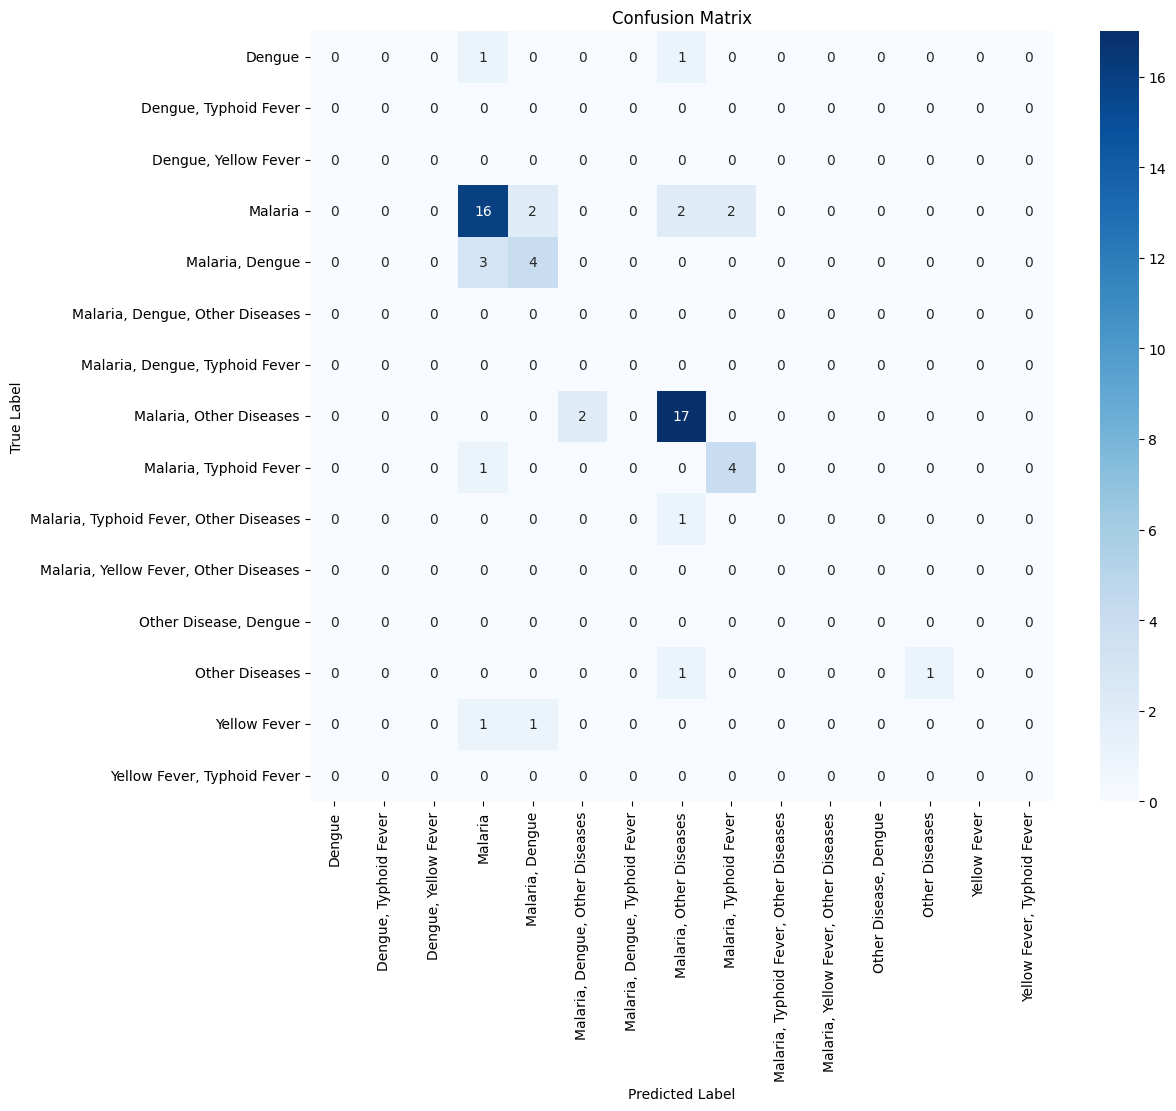


Interpretation of Confusion Matrix:
The confusion matrix shows the counts of true and predicted classifications.
The rows represent the true labels, and the columns represent the predicted labels.
The diagonal elements show the number of correct predictions for each class.
Off-diagonal elements show misclassifications, where the true label is in the row and the predicted label is in the column.

Difficult cases or classes that the model struggled with can be identified by looking at the off-diagonal elements. Large numbers in these cells indicate that instances of a particular true class are frequently being misclassified as another class.


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate the confusion matrix
conf_matrix = confusion_matrix(y_test_cleaned, y_pred_test, labels=pruned_decision_tree_model.classes_)

# Get the class names
class_names = pruned_decision_tree_model.classes_

# Plot the confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

print("\nInterpretation of Confusion Matrix:")
print("The confusion matrix shows the counts of true and predicted classifications.")
print("The rows represent the true labels, and the columns represent the predicted labels.")
print("The diagonal elements show the number of correct predictions for each class.")
print("Off-diagonal elements show misclassifications, where the true label is in the row and the predicted label is in the column.")
print("\nDifficult cases or classes that the model struggled with can be identified by looking at the off-diagonal elements. Large numbers in these cells indicate that instances of a particular true class are frequently being misclassified as another class.")

## Summary:

### Data Analysis Key Findings

* The decision tree model achieved an accuracy of 0.7000, a recall of 0.7000, a precision of 0.6669, and an F1-score of 0.6788 on the test set.
* The most important features for predicting vector-borne diseases according to the model are 'Diagnosed: Other Diseases', 'Age', and 'Pulse rate (mean beats/min ± SD)'.
* The optimal hyperparameter `ccp_alpha` for pruning the decision tree was found to be approximately **0.00717**, which helped in optimizing the model's performance on the test set.
* The confusion matrix provides a visualization of the model's performance across different disease classes, highlighting correct classifications (diagonal elements) and misclassifications (off-diagonal elements). It helps identify which diseases the model struggles to differentiate.